In [5]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


## Лабораторная работа №1
- Напишите программу для распознавания растровых изображений, используя метод k ближайшего соседа (kNN). 
- Реализуйте программно равномерное и неравномерное зашумление изображений и сравните процент распознавания для используемых норм в случаях распознавания растровых бинарных изображений и изображений в градациях серого цвета для различных k. 
- В качестве мер близости используйте предложенные выше и сравните результаты их применения.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [7]:
SEED = 42

df = fetch_openml("mnist_784")

In [8]:
df.target

0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: category
Categories (10, str): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

In [9]:
X = df.data.to_numpy()
y = df.target.to_numpy().astype(int)

X.shape

(70000, 784)

In [10]:
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

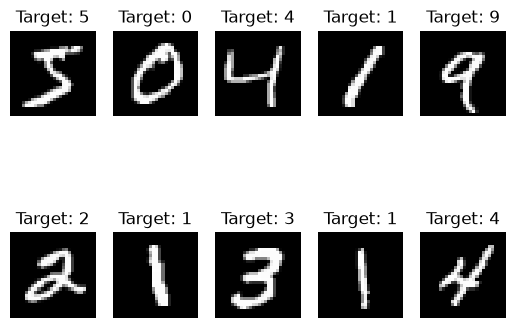

In [11]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Target: {df.target[i]}")
    plt.axis("off")

In [12]:
rng = np.random.default_rng(SEED)
tr = rng.choice(len(X_train), size=10000, replace=False)
te = rng.choice(len(X_test), size=1000, replace=False)

Xtr = (
    X_train[tr]
    .reshape(
        -1,
        28 * 28,
    )
    .astype(np.float32)
) / 255

Xte = (
    X_test[te]
    .reshape(
        -1,
        28 * 28,
    )
    .astype(np.float32)
    / 255
)

ytr, yte = y_train[tr], y_test[te]

Xtr_bin, Xte_bin = (Xtr > 0.5).astype(np.float32), (Xte > 0.5).astype(np.float32)

[(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5)),
 (np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))]

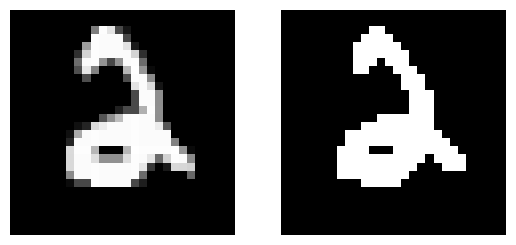

In [13]:
fig, axes = plt.subplots(1, 2)
axes[0].imshow(Xtr[0].reshape(28, 28), cmap="gray")
axes[1].imshow(Xtr_bin[0].reshape(28, 28), cmap="gray")
[ax.axis("off") for ax in axes]

### Функции зашумления: для бинарных и оттенков серого - равномерное и неравномерное

In [ ]:
def noise_uni_bin(X, p=0.1):
    """Равномерное зашумление бинарного изображения с вероятностью p"""
    mask = rng.random(X.shape) < p
    return np.where(mask, 1 - X, X)


def make_map(v_max):
    t = np.arange(28) / 27
    m = t[None, :]
    return np.broadcast_to(m, (28, 28)).ravel() * v_max


def noise_nonuni_bin(X, p_max=0.5):
    """Нерaвномерное зашумление бинарного изображения с вероятностью p_max"""
    mask = rng.random(X.shape) < make_map(p_max)
    return np.where(mask, 1 - X, X)


def noise_uni_gray(X, p=0.1):
    """Равномерное зашумление серого (255) изображения с вероятностью p"""
    mask = rng.random(X.shape) < p
    return np.where(mask, rng.random(X.shape), X)


def noise_nonuni_gray(X, p_max=0.5):
    """Нерaвномерное зашумление серого (255) изображения с вероятностью p_max"""
    mask = rng.random(X.shape) < make_map(p_max)
    return np.where(mask, rng.random(X.shape), X)

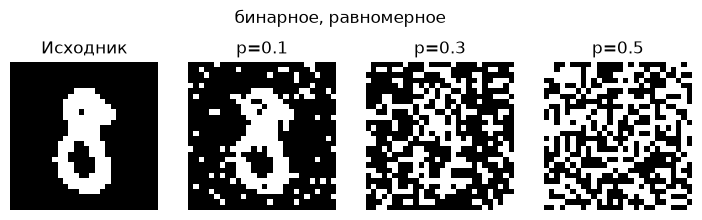

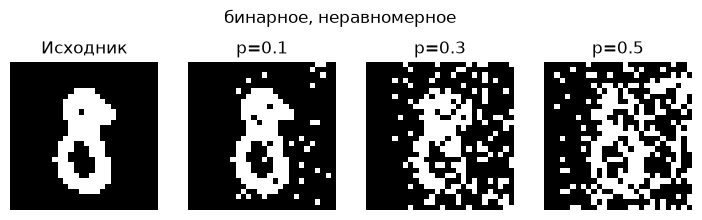

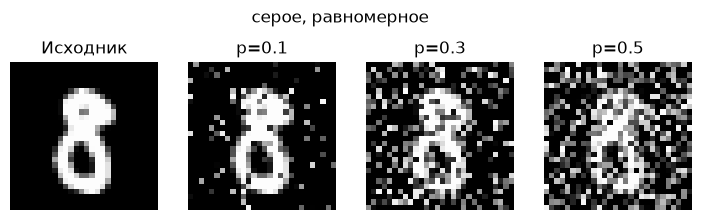

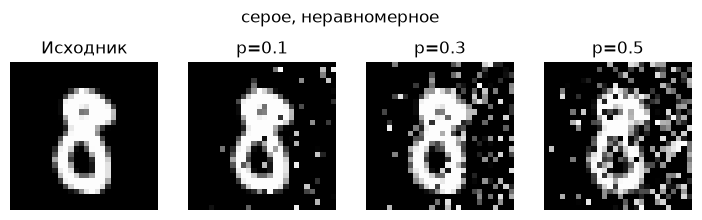

In [ ]:
i = 0


def show_noise(x, fn, levels=(0.1, 0.3, 0.5), title=""):
    fig, axes = plt.subplots(1, len(levels) + 1, figsize=(2.2 * (len(levels) + 1), 2.6))
    axes[0].imshow(x.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Исходник")
    for ax, p in zip(axes[1:], levels):
        ax.imshow(fn(x, p).reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"p={p}")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


show_noise(Xte_bin[i], noise_uni_bin, title="бинарное, равномерное")
show_noise(Xte_bin[i], noise_nonuni_bin, title="бинарное, неравномерное")
show_noise(Xte[i], noise_uni_gray, title="серое, равномерное")
show_noise(Xte[i], noise_nonuni_gray, title="серое, неравномерное")

### Функции расстояния.
*Меры:*
- Евклидово	```p(a, b) = √Σ(aᵢ − bᵢ)²```
- Квадрат евклидова	```p(a, b) = Σ(aᵢ − bᵢ)²```
- Взвешенное евклидово	```p(a, b) = √Σ wᵢ(aᵢ − bᵢ)²```
- Манхэттенское	```p(a, b) = Σ|aᵢ − bᵢ|```
- Чебышёва	```p(a, b) = max|aᵢ − bᵢ|```

In [ ]:
def euclidean(A, B, squared=False):
    a2 = (A**2).sum(axis=1)[:, None]
    b2 = (B**2).sum(axis=1)[None, :]
    d2 = a2 + b2 - 2.0 * (A @ B.T)
    np.maximum(d2, 0, out=d2)
    return d2 if squared else np.sqrt(d2)


def manhattan(A, B): ...


def weighted_euclidean(A, B, w, squared=False):
    s = np.sqrt(w).astype(np.float32)
    return euclidean(s * A, s * B, squared=squared)